# 03 · Comparación NLTK vs spaCy y Eje A (géneros) — Persona 3

**Qué hace este cuaderno:**
1. Carga el POS tagging que dejó Persona 2 (`pos_analysis.csv.gz`).
2. Mide cuánto coinciden NLTK y spaCy (concordancia + Cohen's kappa).
3. Dibuja la matriz de confusión.
4. Elige 10 discrepancias y 50 tokens para revisar a mano.
5. Hace el **Eje A**: comparación entre géneros.



## 1. Cargar los datos

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import os

os.makedirs("../outputs", exist_ok=True)

tokens = pd.read_csv("../data/processed/pos_analysis.csv.gz")
resenas = pd.read_csv("../data/processed/resenas_es.csv", usecols=["id", "genero", "periodo", "paquete"])

print(tokens.shape)
tokens.head()

(1361253, 7)


,id,oracion,token,lema,upos_spacy,morf,upos_nltk
0,1,0,Vi,ver,VERB,Mood=Ind|Number=Sing|Person=1|Tense=Past|VerbF...,VERB
1,1,0,esta,este,DET,Gender=Fem|Number=Sing|PronType=Dem,DET
2,1,0,película,película,NOUN,Gender=Fem|Number=Sing,NOUN
3,1,0,por,por,ADP,NaN,ADP
4,1,0,primera,primero,ADJ,Gender=Fem|NumType=Ord|Number=Sing,ADJ


**Nota importante:** Persona 2 ya etiquetó los mismos tokens con spaCy y con NLTK, y ambos usan el
mismo conjunto de etiquetas (UPOS). Por eso **no hace falta alinear tokens**: cada fila ya tiene las dos etiquetas.

## 2. Concordancia entre NLTK y spaCy

In [6]:
# Quitamos la puntuación (es trivial y infla el porcentaje), igual que hizo Persona 2
palabras = tokens[tokens["upos_spacy"] != "PUNCT"].copy()
palabras["coincide"] = palabras["upos_spacy"] == palabras["upos_nltk"]

concordancia = palabras["coincide"].mean()
kappa = cohen_kappa_score(palabras["upos_spacy"], palabras["upos_nltk"])

print(f"Tokens comparados (sin puntuación): {len(palabras):,}")
print(f"Concordancia simple: {concordancia:.1%}")
print(f"Cohen's kappa:       {kappa:.3f}")

Tokens comparados (sin puntuación): 1,202,657
Concordancia simple: 82.3%
Cohen's kappa:       0.798


NLTK y spaCy coinciden en el 82.3% de las palabras (kappa 0.798), un acuerdo bueno. La mayoría de los errores son de NLTK.

In [7]:
# Concordancia por etiqueta de spaCy: ¿en qué categorías se llevan peor?
por_etiqueta = (palabras.groupby("upos_spacy")["coincide"]
                .agg(["mean", "size"])
                .rename(columns={"mean": "concordancia", "size": "tokens"})
                .sort_values("concordancia"))
por_etiqueta["concordancia"] = (por_etiqueta["concordancia"] * 100).round(1)
por_etiqueta

,concordancia,tokens
upos_spacy,,
PART,0.0,314
SYM,0.0,2180
X,0.0,3
PROPN,8.3,78347
INTJ,19.8,1497
NUM,46.8,9052
ADJ,66.3,102524
VERB,70.7,122881
AUX,72.2,70301


## 3. Matriz de confusión

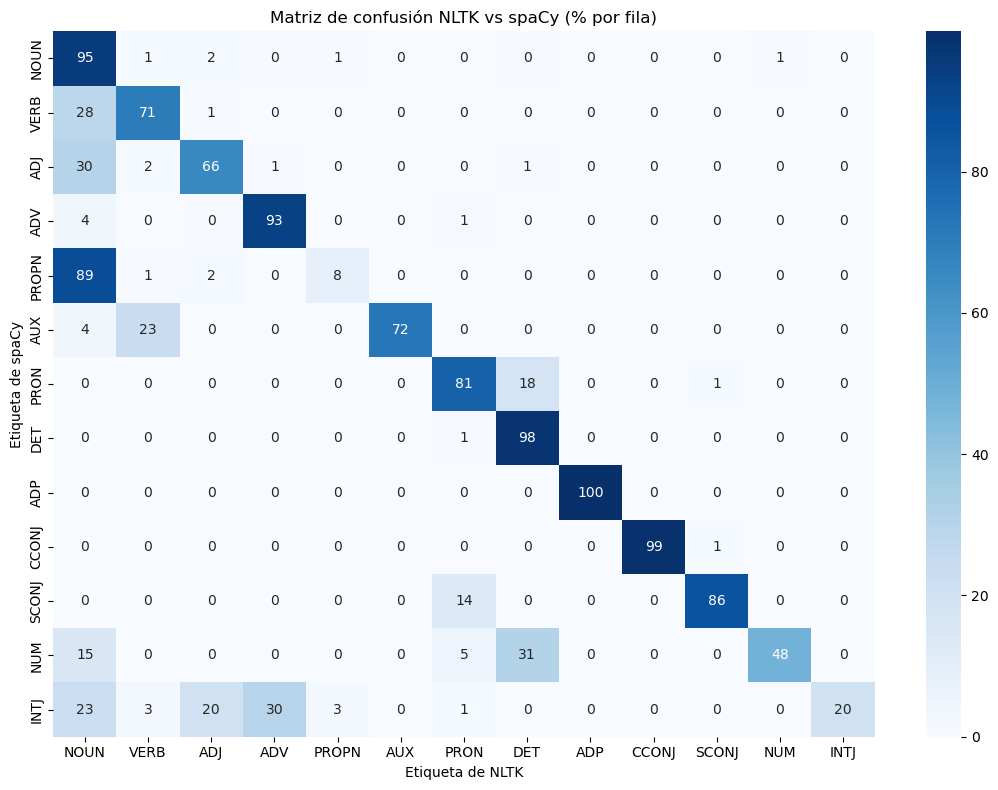

In [9]:
etiquetas = ["NOUN", "VERB", "ADJ", "ADV", "PROPN", "AUX", "PRON", "DET", "ADP", "CCONJ", "SCONJ", "NUM", "INTJ"]
sub = palabras[palabras["upos_spacy"].isin(etiquetas) & palabras["upos_nltk"].isin(etiquetas)]

matriz = confusion_matrix(sub["upos_spacy"], sub["upos_nltk"], labels=etiquetas)
# Normalizamos por fila: de todo lo que spaCy llama X, ¿qué % le pone NLTK a cada etiqueta?
matriz_pct = matriz / matriz.sum(axis=1, keepdims=True) * 100

plt.figure(figsize=(11, 8))
sns.heatmap(matriz_pct, annot=True, fmt=".0f", cmap="Blues",
            xticklabels=etiquetas, yticklabels=etiquetas)
plt.xlabel("Etiqueta de NLTK")
plt.ylabel("Etiqueta de spaCy")
plt.title("Matriz de confusión NLTK vs spaCy (% por fila)")
plt.tight_layout()
plt.savefig("../outputs/matriz_confusion_nltk_spacy.png", dpi=150)
plt.show()

In [10]:
# Los pares de confusión más frecuentes (spaCy -> NLTK)
desacuerdos = palabras[~palabras["coincide"]]
top_pares = (desacuerdos.groupby(["upos_spacy", "upos_nltk"]).size()
             .sort_values(ascending=False).head(10).reset_index(name="veces"))
top_pares

,upos_spacy,upos_nltk,veces
0,PROPN,NOUN,69249
1,VERB,NOUN,34987
2,ADJ,NOUN,30867
3,AUX,VERB,16334
4,PRON,DET,15037
5,SCONJ,PRON,5506
6,NOUN,ADJ,3954
7,ADV,NOUN,3484
8,AUX,NOUN,2922
9,NUM,DET,2707


**Para tu informe:** NLTK le pone "sustantivo" a muchas palabras que spaCy marca como nombres propios, verbos o adjetivos. Pasa porque solo conoce las palabras de su entrenamiento y, si no conoce una, dice "sustantivo".

## 4. Diez discrepancias

In [11]:
# Frase completa de cada token para tener contexto
frases = (tokens.groupby(["id", "oracion"], sort=False)["token"]
          .apply(lambda s: " ".join(s)).rename("frase").reset_index())

desacuerdos = desacuerdos.merge(frases, on=["id", "oracion"], how="left")

# 10 discrepancias al azar (semilla fija = siempre salen las mismas)
diez = desacuerdos.sample(10, random_state=42)[["id", "token", "upos_spacy", "upos_nltk", "frase"]].copy()
diez["cual_es_correcta"] = ""   # se llena en la celda siguiente
diez["por_que_difieren"] = ""   # se llena en la celda siguiente

diez.to_csv("../outputs/10_discrepancias.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.max_colwidth", 120)
diez

,id,token,upos_spacy,upos_nltk,frase,cual_es_correcta,por_que_difieren
169136,5061,Sé,AUX,VERB,"Sé que esto no es el favorito de todos , y algunas escenas me irritaron , como Clark escalando la presa Hoover , per...",,
100172,3013,magnífica,ADJ,NOUN,Esta película también tiene un magnífico giro al final ( nunca la verás venir pero es magnífica ) Fue filmada maravi...,,
94652,2844,Creepers,PROPN,NOUN,""" Creepers 2 "" salta a la acción tan rápido como la primera película , y el Creeper es aún más una creación inquieta...",,
33104,1008,enojarse,VERB,NOUN,Tiene que ser alguien que se divierta en enojarse .,,
9477,293,Totoro,PROPN,NOUN,"¡ También te recordará la infancia y tu propia casa ! Mi vecino Totoro es la historia de Satsuki y Mei , dos hermana...",,
128874,3859,tierra,NOUN,PROPN,Le pasaba la tierra y la tradición a su hijo Tadgh McCabe ( Sean Bean ) .,,
68392,2042,pienses,VERB,NOUN,¡ Ni siquiera lo pienses ! Disfruta del cuento de hadas .,,
170362,5099,es,AUX,NOUN,"Por un lado , yo diría que este es el tipo de película que sólo podría haber sido hecha en los años 50 o 60 .",,
17494,539,equivocado,ADJ,VERB,Dos parejas y la chica de repuesto Jessie ( Eliza Dushku ) en el camino para enfrentarse al novio errante de este úl...,,
162713,4867,Gustavo,PROPN,NOUN,"Y la banda sonora de Gustavo Santaolalla ... "" Las Alas "" laceran cualquier corazón .",,


In [18]:
d = pd.read_csv("../outputs/10_discrepancias.csv")

d["cual_es_correcta"] = ["nltk", "spacy", "spacy", "spacy", "spacy", "spacy", "spacy", "spacy", "spacy", "spacy"]

d["por_que_difieren"] = [
    "Es el verbo saber (yo sé). spaCy lo confundió con el verbo ser/estar por la forma 'sé'.",
    "Adjetivo ('es magnífica'). NLTK pone sustantivo cuando no conoce la palabra o es un adjetivo derivado.",
    "Nombre propio (título de película). NLTK no reconoce nombres propios fuera de su corpus.",
    "Verbo en infinitivo. NLTK lo tomó como sustantivo porque el infinitivo 'se' + verbo es ambiguo.",
    "Nombre propio (personaje de película). NLTK lo marcó como sustantivo común.",
    "Sustantivo común ('la tierra'). NLTK lo marcó como nombre propio por ser tierra/Tierra.",
    "Verbo en subjuntivo ('no lo pienses'). NLTK no reconoce formas conjugadas poco frecuentes.",
    "Verbo copulativo 'es' (auxiliar en UPOS). NLTK lo etiquetó como sustantivo por error de contexto.",
    "Adjetivo ('el giro equivocado'). NLTK lo tomó como participio verbal.",
    "Nombre propio (persona). NLTK lo marcó como sustantivo común.",
]

d.to_csv("../outputs/10_discrepancias.csv", index=False, encoding="utf-8-sig")
d[["token", "upos_spacy", "upos_nltk", "cual_es_correcta"]]

,token,upos_spacy,upos_nltk,cual_es_correcta
0,Sé,AUX,VERB,nltk
1,magnífica,ADJ,NOUN,spacy
2,Creepers,PROPN,NOUN,spacy
3,enojarse,VERB,NOUN,spacy
4,Totoro,PROPN,NOUN,spacy
5,tierra,NOUN,PROPN,spacy
6,pienses,VERB,NOUN,spacy
7,es,AUX,NOUN,spacy
8,equivocado,ADJ,VERB,spacy
9,Gustavo,PROPN,NOUN,spacy


**Revisión manual:** en cada caso se leyó la frase, se eligió la etiqueta correcta y se explicó por qué difieren. Todo está en `outputs/10_discrepancias.csv`.

## 5. Cincuenta tokens revisados

In [12]:
# 50 tokens al azar de TODO el corpus (sin puntuación), coincidan o no
cincuenta = palabras.merge(frases, on=["id", "oracion"], how="left").sample(50, random_state=7)
cincuenta = cincuenta[["id", "token", "upos_spacy", "upos_nltk", "frase"]].copy()
cincuenta["etiqueta_correcta"] = ""   # se llena en la celda siguiente

cincuenta.to_csv("../outputs/50_tokens_revisados.csv", index=False, encoding="utf-8-sig")
cincuenta.head(10)

,id,token,upos_spacy,upos_nltk,frase,etiqueta_correcta
728,4,en,ADP,ADP,"Eliza Dushku , o cualquiera que fuera su nombre , era brillante en esto , había escenas en las que se sentía como si...",
373963,1987,un,DET,DET,"Pero , un hombre egoísta llamado Gaston , que ha estado enamorado de Belle , no lo aprueba , y sus planes casi preva...",
244159,1299,buenas,ADJ,ADJ,"De todos modos , si vas a ver Gone en 60 segundos para los coches , ahorra tu dinero para otra cosa , si no estás pu...",
265221,1410,Washington,PROPN,PROPN,"Smith va a Washington es un placer ver no sólo su historia , sino también el genio actor que fue Jimmy Stewart .",
668917,3554,y,CCONJ,CCONJ,He buscado y la coincidencia más cercana que he encontrado es una que muestra algunas bolas de rebote severamente bi...,
512771,2725,ha,AUX,AUX,También debo cantar elogios para la compañía de producción esto sale de- Título de trabajo ha salido con algunas de ...,
881075,4673,horrible,ADJ,ADJ,"Un legado de vergüenza , pasó de una víctima a la siguiente todo para que algún horrible sociópata pueda recaudar in...",
219210,1179,soplo,NOUN,NOUN,"La historia es un soplo de aire fresco de la historia habitual de Hollywood , y el hecho de que una película que se ...",
534002,2839,buen,ADJ,ADJ,"Hay buen trabajo de apoyo también de Jay Baruchel como Danger Barch , que sueña con ser un campeón del mundo y Margo...",
1049718,5575,la,DET,DET,"En cuanto a actuar , esta película era la correcta .",


In [19]:
r = pd.read_csv("../outputs/50_tokens_revisados.csv")

r["etiqueta_correcta"] = [
    "ADP", "DET", "ADJ", "PROPN", "CCONJ", "AUX", "ADJ", "NOUN", "ADJ", "DET",
    "DET", "ADV", "SCONJ", "PROPN", "DET", "SCONJ", "ADV", "NOUN", "NOUN", "NOUN",
    "ADV", "ADP", "NOUN", "VERB", "ADV", "ADJ", "CCONJ", "ADP", "NUM", "CCONJ",
    "NOUN", "DET", "NOUN", "PRON", "NOUN", "NOUN", "ADP", "ADV", "NOUN", "NOUN",
    "ADP", "ADP", "ADV", "ADP", "VERB", "ADP", "ADP", "DET", "VERB", "PRON",
]

r.to_csv("../outputs/50_tokens_revisados.csv", index=False, encoding="utf-8-sig")

print(f"Tokens revisados: {len(r)}")
print(f"Exactitud spaCy: {(r['upos_spacy'] == r['etiqueta_correcta']).mean():.1%}")
print(f"Exactitud NLTK:  {(r['upos_nltk'] == r['etiqueta_correcta']).mean():.1%}")

# Los tokens donde alguna herramienta falló
r[(r["upos_spacy"] != r["etiqueta_correcta"]) | (r["upos_nltk"] != r["etiqueta_correcta"])][["token", "upos_spacy", "upos_nltk", "etiqueta_correcta"]]


Tokens revisados: 50
Exactitud spaCy: 98.0%
Exactitud NLTK:  88.0%


,token,upos_spacy,upos_nltk,etiqueta_correcta
12,IF,SYM,NOUN,SCONJ
13,Star,PROPN,NOUN,PROPN
16,poco,ADV,PRON,ADV
30,diciembre,NOUN,NUM,NOUN
44,pagué,VERB,NOUN,VERB
48,encanta,VERB,NOUN,VERB


De 50 palabras revisadas, spaCy acertó 98% y NLTK 88%. El único error de spaCy fue la palabra en inglés "IF".

In [13]:
# Córrela SOLO después de llenar la columna etiqueta_correcta en el CSV y guardarlo
rev = pd.read_csv("../outputs/50_tokens_revisados.csv")
rev = rev[rev["etiqueta_correcta"].notna() & (rev["etiqueta_correcta"] != "")]

if len(rev) == 0:
    print("Aún no has llenado la columna etiqueta_correcta.")
else:
    print(f"Tokens revisados: {len(rev)}")
    print(f"Exactitud spaCy: {(rev['upos_spacy'] == rev['etiqueta_correcta']).mean():.1%}")
    print(f"Exactitud NLTK:  {(rev['upos_nltk'] == rev['etiqueta_correcta']).mean():.1%}")

Aún no has llenado la columna etiqueta_correcta.


## 6. Eje A: comparación entre géneros

Compara cómo cambia la distribución gramatical según el género de la película (Action, Animation, Comedy, Drama, Horror).
Usamos las etiquetas de **spaCy** (el modelo más preciso) y quitamos puntuación.

In [14]:
t = tokens.merge(resenas[["id", "genero"]], on="id", how="inner")
t = t[~t["upos_spacy"].isin(["PUNCT", "SPACE", "SYM"])]

categorias = ["NOUN", "VERB", "ADJ", "ADV", "PRON", "PROPN", "AUX"]

conteo = t.groupby(["genero", "upos_spacy"]).size().unstack(fill_value=0)
total = conteo.sum(axis=1)
porcentajes = (conteo[categorias].div(total, axis=0) * 100).round(2)
porcentajes

upos_spacy,NOUN,VERB,ADJ,ADV,PRON,PROPN,AUX
genero,,,,,,,
Action,18.76,9.96,8.54,6.79,6.77,7.24,5.85
Animation,18.71,10.00,8.72,6.82,6.90,6.57,5.83
Comedy,18.21,10.28,8.48,6.71,7.14,7.49,5.87
Drama,19.04,10.40,8.53,6.67,7.17,6.05,5.72
Horror,19.19,10.54,8.42,7.10,7.26,5.35,6.00


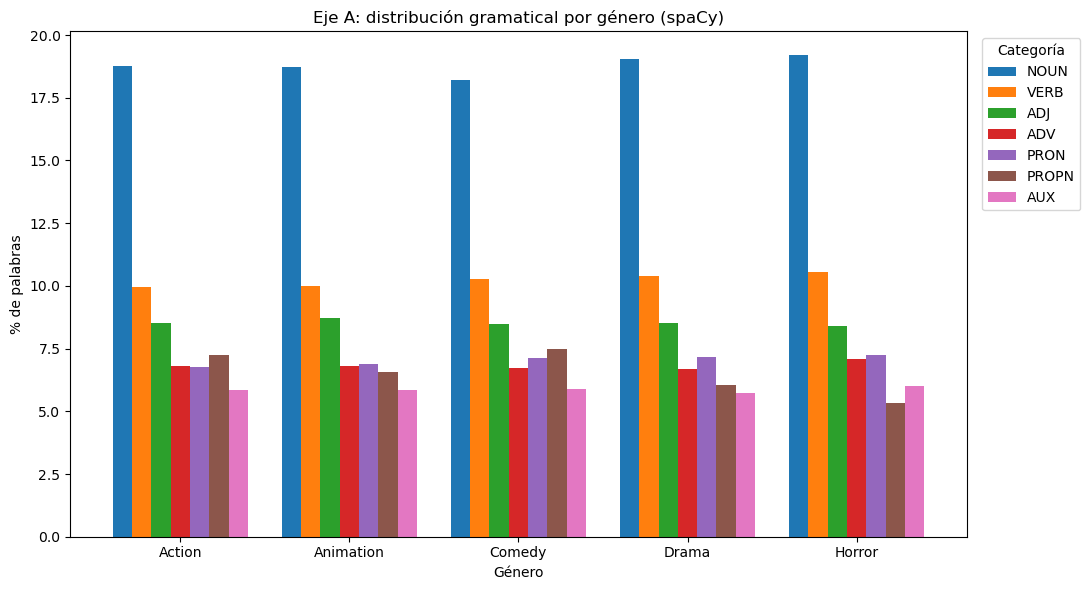

In [15]:
# Gráfico: % de cada categoría gramatical por género
ax = porcentajes.plot(kind="bar", figsize=(11, 6), width=0.8)
ax.set_ylabel("% de palabras")
ax.set_xlabel("Género")
ax.set_title("Eje A: distribución gramatical por género (spaCy)")
plt.xticks(rotation=0)
plt.legend(title="Categoría", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../outputs/eje_A_generos.png", dpi=150)
plt.show()

In [16]:
# Dos índices fáciles de interpretar por género
indices = pd.DataFrame({
    "adj_por_100": (conteo["ADJ"] / total * 100).round(2),
    "adv_por_100": (conteo["ADV"] / total * 100).round(2),
    "ratio_adj_sustantivo": (conteo["ADJ"] / conteo["NOUN"]).round(3),
    "ratio_verbo_sustantivo": (conteo["VERB"] / conteo["NOUN"]).round(3),
})
indices

,adj_por_100,adv_por_100,ratio_adj_sustantivo,ratio_verbo_sustantivo
genero,,,,
Action,8.54,6.79,0.455,0.531
Animation,8.72,6.82,0.466,0.535
Comedy,8.48,6.71,0.466,0.565
Drama,8.53,6.67,0.448,0.546
Horror,8.42,7.10,0.439,0.549


In [17]:
# Guardamos las tablas para que quien arme el dashboard de Plotly las use
porcentajes.reset_index().to_csv("../outputs/eje_A_porcentajes_por_genero.csv", index=False, encoding="utf-8-sig")
indices.reset_index().to_csv("../outputs/eje_A_indices_por_genero.csv", index=False, encoding="utf-8-sig")
print("Listo: tablas guardadas en outputs/")

Listo: tablas guardadas en outputs/


**Eje A:** los géneros se parecen mucho en su gramática. Los adjetivos casi no cambian. Horror usa más adverbios y verbos y menos nombres propios; Comedy usa más nombres propios.

**Conclusión general:** spaCy etiqueta mejor que NLTK, sobre todo con nombres propios, porque NLTK solo conoce las palabras de su entrenamiento.